# Location-Based House Price Prediction Using ANN

I am using this notebook to understand how a property's location, area, number of bedrooms, and available facilities relate to its price. After the initial analysis, I will train an Artificial Neural Network (ANN) to estimate house prices.

The dataset is **`house_data.csv`**. Keep it in the same folder as this notebook.

The dataset contains listings from six cities. The `Price` column is the value to predict. I will keep prices in the dataset's original units because the file does not include a clear currency/unit description.

### 1. Import the libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

np.random.seed(42)
tf.keras.utils.set_random_seed(42)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 80)

### 2. Load the dataset

In [2]:
df = pd.read_csv("data/house_data.csv")

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
df.head()

Rows: 32963
Columns: 41


,Price,Area,Location,No. of Bedrooms,Resale,MaintenanceStaff,Gymnasium,SwimmingPool,LandscapedGardens,JoggingTrack,RainWaterHarvesting,IndoorGames,ShoppingMall,Intercom,SportsFacility,ATM,ClubHouse,School,24X7Security,PowerBackup,CarParking,StaffQuarter,Cafeteria,MultipurposeRoom,Hospital,WashingMachine,Gasconnection,AC,Wifi,Children'splayarea,LiftAvailable,BED,VaastuCompliant,Microwave,GolfCourse,TV,DiningTable,Sofa,Wardrobe,Refrigerator,City
0,30000000,3340,JP Nagar Phase 1,4,0,1,1,1,1,1,1,1,0,1,1,0,1,0,1,1,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,Bangalore
1,7888000,1045,Dasarahalli on Tumkur Road,2,0,0,1,1,1,1,1,1,0,0,1,0,1,0,1,1,1,0,0,1,0,0,0,0,0,1,1,0,1,0,0,0,0,0,0,0,Bangalore
2,4866000,1179,Kannur on Thanisandra Main Road,2,0,0,1,1,1,1,1,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,Bangalore
3,8358000,1675,Doddanekundi,3,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,Bangalore
4,6845000,1670,Kengeri,3,0,1,1,1,1,1,1,1,0,1,1,0,1,0,1,1,1,0,0,1,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,Bangalore


### 3. Get familiar with the data

In [3]:
print("Column names:")
print(df.columns.tolist())

print("\nData types and non-null values:")
df.info()

display(df.describe(include="all").T)

Column names:
['Price', 'Area', 'Location', 'No. of Bedrooms', 'Resale', 'MaintenanceStaff', 'Gymnasium', 'SwimmingPool', 'LandscapedGardens', 'JoggingTrack', 'RainWaterHarvesting', 'IndoorGames', 'ShoppingMall', 'Intercom', 'SportsFacility', 'ATM', 'ClubHouse', 'School', '24X7Security', 'PowerBackup', 'CarParking', 'StaffQuarter', 'Cafeteria', 'MultipurposeRoom', 'Hospital', 'WashingMachine', 'Gasconnection', 'AC', 'Wifi', "Children'splayarea", 'LiftAvailable', 'BED', 'VaastuCompliant', 'Microwave', 'GolfCourse', 'TV', 'DiningTable', 'Sofa', 'Wardrobe', 'Refrigerator', 'City']

Data types and non-null values:
<class 'pandas.DataFrame'>
RangeIndex: 32963 entries, 0 to 32962
Data columns (total 41 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Price                32963 non-null  int64
 1   Area                 32963 non-null  int64
 2   Location             32963 non-null  str  
 3   No. of Bedrooms      32963 non-null  in

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Price,32963.0,NaN,NaN,NaN,11686718.076055,23073681.526228,2000000.0,4071500.0,6711000.0,12000000.0,854599999.0
Area,32963.0,NaN,NaN,NaN,1293.362194,763.703754,200.0,853.0,1125.0,1500.0,16000.0
Location,32963,1776,Noida,761,NaN,NaN,NaN,NaN,NaN,NaN,NaN
No. of Bedrooms,32963.0,NaN,NaN,NaN,2.411765,0.8128,1.0,2.0,2.0,3.0,9.0
Resale,32963.0,NaN,NaN,NaN,0.381397,0.485737,0.0,0.0,0.0,1.0,1.0
MaintenanceStaff,32963.0,NaN,NaN,NaN,6.296454,4.075024,0.0,0.0,9.0,9.0,9.0
Gymnasium,32963.0,NaN,NaN,NaN,6.403725,3.917995,0.0,1.0,9.0,9.0,9.0
SwimmingPool,32963.0,NaN,NaN,NaN,6.371325,3.966385,0.0,1.0,9.0,9.0,9.0
LandscapedGardens,32963.0,NaN,NaN,NaN,6.351151,3.996086,0.0,1.0,9.0,9.0,9.0
JoggingTrack,32963.0,NaN,NaN,NaN,6.346328,4.00314,0.0,1.0,9.0,9.0,9.0


### 4. Check the data quality

In [4]:
missing_report = pd.DataFrame({
    "Missing values": df.isna().sum(),
    "Missing percent": (df.isna().mean() * 100).round(2)
})
display(missing_report)

print("Exact duplicate rows:", df.duplicated().sum())
print("\nNumber of cities:", df["City"].nunique())
print("Number of locations:", df["Location"].nunique())
print("Unique city-location pairs:", df[["City", "Location"]].drop_duplicates().shape[0])

,Missing values,Missing percent
Price,0,0.0
Area,0,0.0
Location,0,0.0
No. of Bedrooms,0,0.0
Resale,0,0.0
MaintenanceStaff,0,0.0
Gymnasium,0,0.0
SwimmingPool,0,0.0
LandscapedGardens,0,0.0
JoggingTrack,0,0.0


Exact duplicate rows: 3828

Number of cities: 6
Number of locations: 1776
Unique city-location pairs: 1790


### 5. Clean the data

In [5]:
df = df.copy()

# Clean text fields so that 'Area Name' and 'Area Name ' are not treated as different places.
df["City"] = df["City"].astype("string").str.strip()
df["Location"] = df["Location"].astype("string").str.strip()
df["City"] = df["City"].replace("", pd.NA)
df["Location"] = df["Location"].replace("", pd.NA)

# Make sure the main numeric columns contain numbers.
df["Price"] = pd.to_numeric(df["Price"], errors="coerce")
df["Area"] = pd.to_numeric(df["Area"], errors="coerce")
df["No. of Bedrooms"] = pd.to_numeric(df["No. of Bedrooms"], errors="coerce")

# Price and area must be positive to be useful for this prediction task.
df = df.dropna(subset=["Price", "Area", "No. of Bedrooms", "City", "Location"])
df = df[(df["Price"] > 0) & (df["Area"] > 0)]
df = df[df["City"].ne("") & df["Location"].ne("")]

before_duplicates = len(df)
df = df.drop_duplicates().reset_index(drop=True)

print("Rows removed as exact duplicates:", before_duplicates - len(df))
print("Rows after basic cleaning:", len(df))
print("Price range:", df["Price"].min(), "to", df["Price"].max())
print("Area range:", df["Area"].min(), "to", df["Area"].max())

Rows removed as exact duplicates: 3828
Rows after basic cleaning: 29135
Price range: 2000000 to 854599999
Area range: 200 to 16000


### 6. Check the amenity columns

The amenity columns mostly contain 0, 1, and 9. In this dataset, I will treat `9` as an unknown/not-provided value rather than assuming it means the facility is available or unavailable. This is a working assumption; a dataset data dictionary would be needed to confirm the original meaning of `9`.

In [6]:
amenity_cols = [
    col for col in df.columns
    if col not in ["Price", "Area", "Location", "No. of Bedrooms", "Resale", "City"]
]

amenity_value_counts = pd.DataFrame({
    "Zero": (df[amenity_cols] == 0).sum(),
    "One": (df[amenity_cols] == 1).sum(),
    "Code_9": (df[amenity_cols] == 9).sum()
})
display(amenity_value_counts.head(12))

print("Amenity columns checked:", len(amenity_cols))
print("Rows containing at least one code 9:", int((df[amenity_cols] == 9).any(axis=1).sum()))

,Zero,One,Code_9
MaintenanceStaff,6823,1403,20909
Gymnasium,3866,4360,20909
SwimmingPool,4743,3483,20909
LandscapedGardens,5253,2973,20909
JoggingTrack,5400,2826,20909
RainWaterHarvesting,5169,3057,20909
IndoorGames,5947,2279,20909
ShoppingMall,7559,667,20909
Intercom,4406,3820,20909
SportsFacility,5926,2300,20909


Amenity columns checked: 35
Rows containing at least one code 9: 20909


### 7. Create a few helpful columns

In [7]:
# Count facilities that are explicitly marked as available.
# Count code 9 separately so unknown values are not mistaken for facilities.
df["Amenity_Yes_Count"] = (df[amenity_cols] == 1).sum(axis=1)
df["Amenity_Unknown_Count"] = (df[amenity_cols] == 9).sum(axis=1)

# Combine city and locality so a place name shared by two cities is not mixed up.
df["City_Location"] = df["City"] + " | " + df["Location"]

# Price per unit area is useful for comparing houses of different sizes.
df["Price_per_Area"] = df["Price"] / df["Area"]

display(df[[
    "City", "Location", "City_Location", "Area", "No. of Bedrooms",
    "Amenity_Yes_Count", "Amenity_Unknown_Count", "Price_per_Area", "Price"
]].head())

,City,Location,City_Location,Area,No. of Bedrooms,Amenity_Yes_Count,Amenity_Unknown_Count,Price_per_Area,Price
0,Bangalore,JP Nagar Phase 1,Bangalore | JP Nagar Phase 1,3340,4,14,0,8982.035928,30000000
1,Bangalore,Dasarahalli on Tumkur Road,Bangalore | Dasarahalli on Tumkur Road,1045,2,15,0,7548.325359,7888000
2,Bangalore,Kannur on Thanisandra Main Road,Bangalore | Kannur on Thanisandra Main Road,1179,2,9,0,4127.226463,4866000
3,Bangalore,Doddanekundi,Bangalore | Doddanekundi,1675,3,3,0,4989.850746,8358000
4,Bangalore,Kengeri,Bangalore | Kengeri,1670,3,16,0,4098.802395,6845000


### 8. Understand house prices

,Price
count,2.913500e+04
mean,1.195267e+07
std,2.387647e+07
min,2.000000e+06
25%,4.179999e+06
50%,6.884999e+06
75%,1.230000e+07
90%,2.250000e+07
95%,3.310000e+07
99%,8.250000e+07


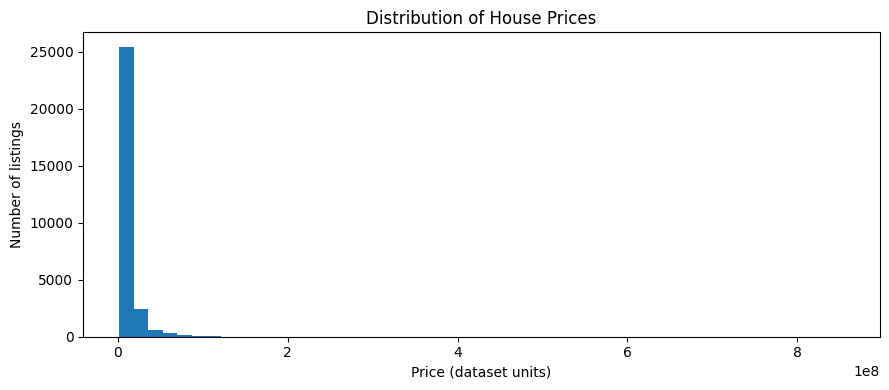

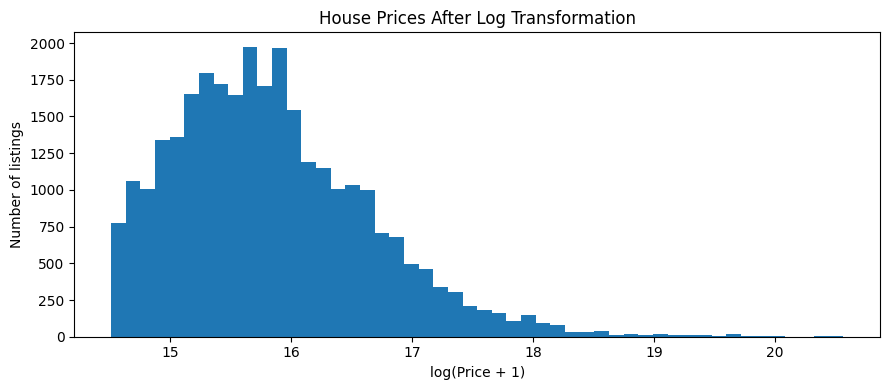

In [8]:
display(df["Price"].describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]).to_frame("Price"))

plt.figure(figsize=(9, 4))
plt.hist(df["Price"], bins=50)
plt.title("Distribution of House Prices")
plt.xlabel("Price (dataset units)")
plt.ylabel("Number of listings")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 4))
plt.hist(np.log1p(df["Price"]), bins=50)
plt.title("House Prices After Log Transformation")
plt.xlabel("log(Price + 1)")
plt.ylabel("Number of listings")
plt.tight_layout()
plt.show()

The price distribution is skewed, with a small number of very expensive listings. I will not delete them automatically. The model will learn on log-transformed prices, and I will convert its predictions back to the original price scale for evaluation.

### 9. Compare prices across cities

,Listings,Median_Price,Average_Price,Median_Area,Median_Price_per_Area
City,,,,,
Mumbai,6925,9500000.0,15256854.28,902.0,10613.60
Hyderabad,1998,7873500.0,10141268.24,1500.0,5110.51
Delhi,4109,7800000.0,18144335.11,1100.0,7001.54
Bangalore,5521,7300000.0,10807086.52,1332.0,5345.08
Chennai,4307,5850000.0,8933744.78,1092.0,5419.42
Kolkata,6275,4923000.0,7908581.17,1137.0,4314.48


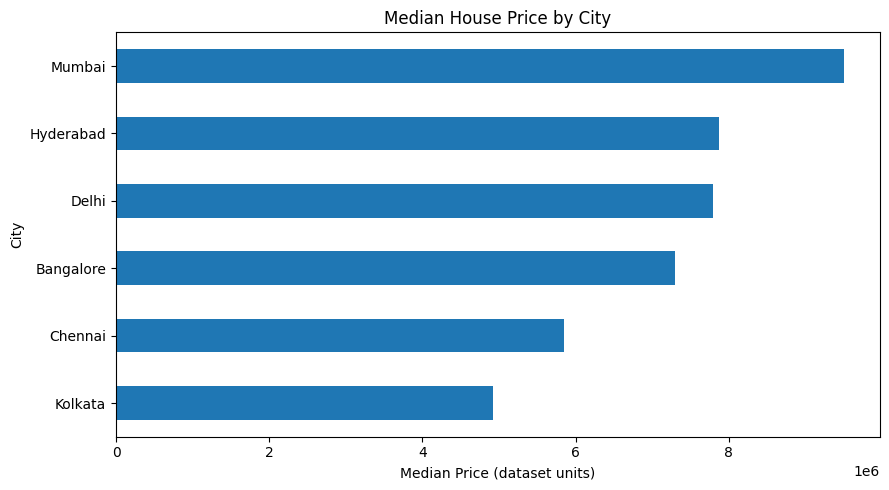

In [9]:
city_summary = df.groupby("City").agg(
    Listings=("Price", "size"),
    Median_Price=("Price", "median"),
    Average_Price=("Price", "mean"),
    Median_Area=("Area", "median"),
    Median_Price_per_Area=("Price_per_Area", "median")
).sort_values("Median_Price", ascending=False)

display(city_summary.round(2))

city_summary["Median_Price"].sort_values().plot(kind="barh", figsize=(9, 5))
plt.title("Median House Price by City")
plt.xlabel("Median Price (dataset units)")
plt.ylabel("City")
plt.tight_layout()
plt.show()

### 10. Find locations with enough listings to compare

A location with only one or two listings can show a misleading average price. For a fairer comparison, I will only rank locations with at least 20 listings.

,City,Location,City_Location,Listings,Median_Price,Average_Price,Median_Area,Median_Price_per_Area
252,Bangalore,Richmond Town,Bangalore | Richmond Town,38,67750000.0,62341473.68,2983.0,22758.54
1763,Mumbai,Worli,Mumbai | Worli,23,55000000.0,65058608.65,2285.0,24375.00
430,Chennai,Raja Annamalai Puram,Chennai | Raja Annamalai Puram,36,43950000.0,37423416.61,2600.0,16049.48
1593,Mumbai,Parel,Mumbai | Parel,38,34500000.0,40020394.68,1177.0,25148.78
859,Hyderabad,Banjara Hills,Hyderabad | Banjara Hills,40,28850000.0,28905000.00,2953.0,9822.65
1748,Mumbai,Ville Parle East,Mumbai | Ville Parle East,72,28000000.0,27537500.00,1092.5,23810.16
1756,Mumbai,Wadala,Mumbai | Wadala,26,27900000.0,25724999.92,1331.0,18438.44
950,Hyderabad,Madhapur,Hyderabad | Madhapur,32,27000000.0,25566093.72,2940.0,9361.25
243,Bangalore,Rajajinagar,Bangalore | Rajajinagar,48,26050000.0,26478166.62,2580.0,8716.87
134,Bangalore,JP Nagar Phase 4,Bangalore | JP Nagar Phase 4,42,25149999.5,27198047.50,3097.0,9495.43


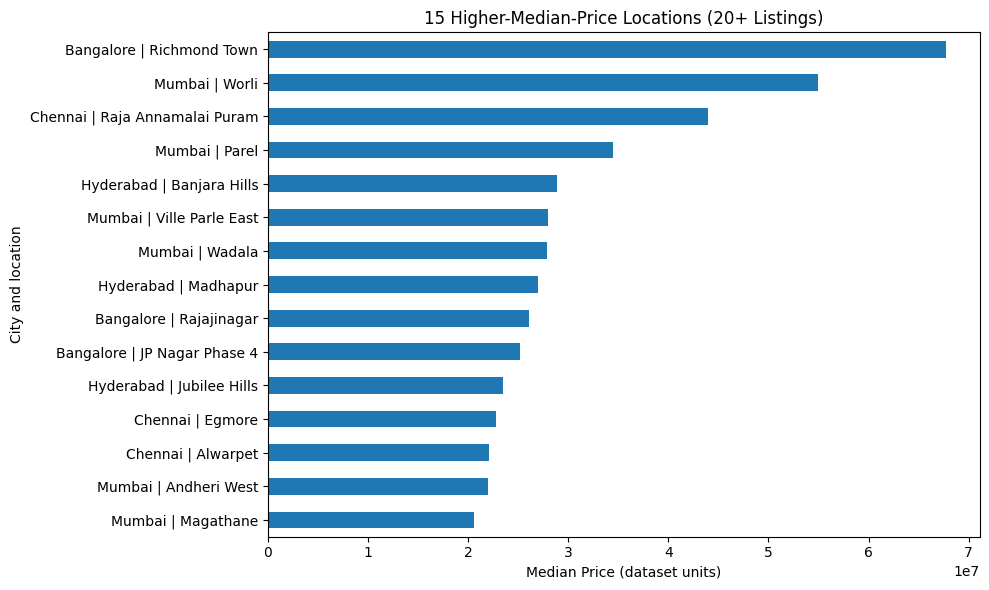

In [10]:
location_summary = df.groupby(["City", "Location", "City_Location"]).agg(
    Listings=("Price", "size"),
    Median_Price=("Price", "median"),
    Average_Price=("Price", "mean"),
    Median_Area=("Area", "median"),
    Median_Price_per_Area=("Price_per_Area", "median")
).reset_index()

location_summary = location_summary[location_summary["Listings"] >= 20]

top_locations = location_summary.sort_values("Median_Price", ascending=False).head(15)
display(top_locations.round(2))

top_locations.sort_values("Median_Price").plot(
    x="City_Location", y="Median_Price", kind="barh", legend=False, figsize=(10, 6)
)
plt.title("15 Higher-Median-Price Locations (20+ Listings)")
plt.xlabel("Median Price (dataset units)")
plt.ylabel("City and location")
plt.tight_layout()
plt.show()

### 11. Check the relationship between area and price

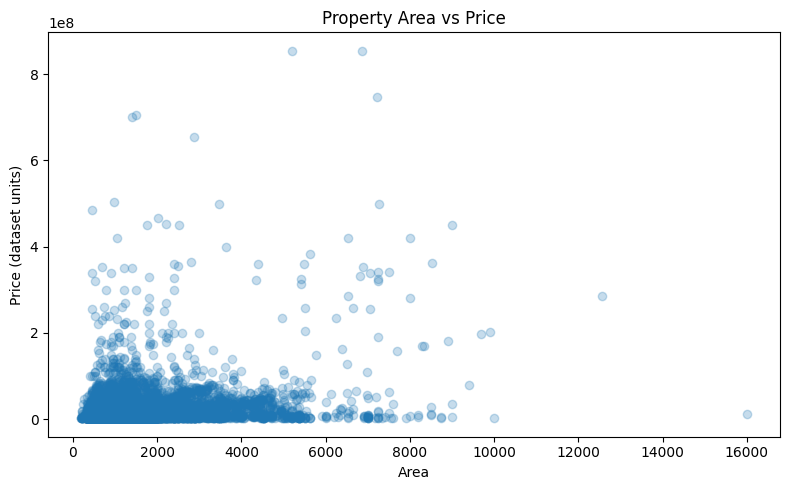

,Listings,Median_Price,Median_Area
Area,,,
"(184.2, 2175.0]",26791,6500000.0,1100.0
"(2175.0, 4150.0]",1949,15500000.0,2621.0
"(4150.0, 6125.0]",304,13900000.0,4736.0
"(6125.0, 8100.0]",71,18000000.0,7000.0
"(8100.0, 10075.0]",18,32000000.0,8750.0
"(12050.0, 14025.0]",1,285400000.0,12552.0
"(14025.0, 16000.0]",1,11200000.0,16000.0


In [11]:
plt.figure(figsize=(8, 5))
plt.scatter(df["Area"], df["Price"], alpha=0.25)
plt.title("Property Area vs Price")
plt.xlabel("Area")
plt.ylabel("Price (dataset units)")
plt.tight_layout()
plt.show()

area_summary = df.groupby(pd.cut(df["Area"], bins=8, duplicates="drop")).agg(
    Listings=("Price", "size"),
    Median_Price=("Price", "median"),
    Median_Area=("Area", "median")
)
display(area_summary.round(2))

### 12. Compare price with number of bedrooms

,No. of Bedrooms,Listings,Median_Price,Average_Price
0,1,3436,6000000.0,9907474.07
1,2,12399,5900000.0,9722289.35
2,3,11217,8000000.0,12281762.02
3,4,1834,13350000.0,22864084.47
4,5,202,14650000.0,59250717.80
5,6,31,13400000.0,40980645.16
6,7,8,15750000.0,22075750.00
7,8,7,50000000.0,76700000.00
8,9,1,2400000.0,2400000.00


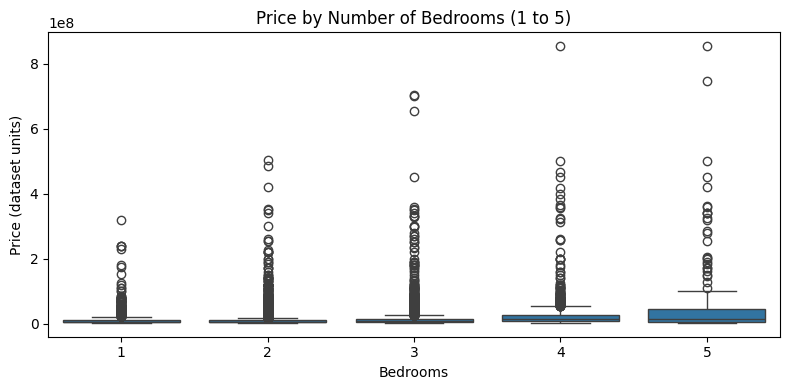

In [12]:
bedroom_summary = df.groupby("No. of Bedrooms").agg(
    Listings=("Price", "size"),
    Median_Price=("Price", "median"),
    Average_Price=("Price", "mean")
).reset_index()

display(bedroom_summary.round(2))

common_bedrooms = df[df["No. of Bedrooms"].between(1, 5)]
plt.figure(figsize=(8, 4))
sns.boxplot(data=common_bedrooms, x="No. of Bedrooms", y="Price")
plt.title("Price by Number of Bedrooms (1 to 5)")
plt.xlabel("Bedrooms")
plt.ylabel("Price (dataset units)")
plt.tight_layout()
plt.show()

### 13. Check whether amenities relate to price

In [13]:
amenity_price = pd.DataFrame({
    "Amenity": amenity_cols,
    "Median_Price_When_Yes": [
        df.loc[df[col] == 1, "Price"].median() for col in amenity_cols
    ],
    "Listings_Marked_Yes": [
        int((df[col] == 1).sum()) for col in amenity_cols
    ],
    "Listings_Marked_No": [
        int((df[col] == 0).sum()) for col in amenity_cols
    ],
    "Listings_Unknown": [
        int((df[col] == 9).sum()) for col in amenity_cols
    ]
})
amenity_price = amenity_price.sort_values("Median_Price_When_Yes", ascending=False)
display(amenity_price.head(15).round(2))

,Amenity,Median_Price_When_Yes,Listings_Marked_Yes,Listings_Marked_No,Listings_Unknown
22,AC,14000000.0,575,7651,20909
21,Gasconnection,13799999.0,1633,6593,20909
20,WashingMachine,12400000.0,403,7823,20909
28,Microwave,11600000.0,456,7770,20909
29,GolfCourse,11200000.0,185,8041,20909
34,Refrigerator,11150000.0,476,7750,20909
33,Wardrobe,11000000.0,187,8039,20909
32,Sofa,11000000.0,484,7742,20909
30,TV,11000000.0,495,7731,20909
23,Wifi,10900000.0,187,8039,20909


### 14. Prepare the data for ANN

The model will predict `Price`. It will use the property's city and location, area, bedrooms, resale status, and available facility information.

I will not use `Price_per_Area` as an input because it is calculated directly from the target price. That would leak the answer into the model and make the results misleading.

In [14]:
# The target is the house price.
y = df["Price"].astype(float)

# Use original location and city information, plus house features.
numeric_features = [
    "Area",
    "No. of Bedrooms",
    "Resale",
    "Amenity_Yes_Count",
    "Amenity_Unknown_Count"
] + amenity_cols

categorical_features = ["City", "City_Location"]

X = df[numeric_features + categorical_features].copy()

# Amenity code 9 means unknown in this workflow, so change it to missing.
for col in amenity_cols:
    X[col] = pd.to_numeric(X[col], errors="coerce").replace(9, np.nan)

for col in numeric_features:
    X[col] = pd.to_numeric(X[col], errors="coerce")

X["City"] = X["City"].astype(str)
X["City_Location"] = X["City_Location"].astype(str)

print("Rows used:", len(X))
print("Input columns:", len(X.columns))
print("Numeric inputs:", len(numeric_features))
print("Categorical inputs:", categorical_features)

Rows used: 29135
Input columns: 42
Numeric inputs: 40
Categorical inputs: ['City', 'City_Location']


### 15. Split training, validation and test data

In [15]:
# Keep test data separate until final evaluation.
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.15, random_state=42
)

# This gives roughly 70% train, 15% validation and 15% test overall.
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.1765, random_state=42
)

print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))
print("Test rows:", len(X_test))

Training rows: 20393
Validation rows: 4371
Test rows: 4371


### 16. Fill missing values, scale numbers and encode locations

In [16]:
numeric_pipeline = Pipeline([
    ("fill_missing", SimpleImputer(strategy="median", add_indicator=True)),
    ("scale", StandardScaler())
])

# Group locations with fewer than 10 rows into an infrequent category.
try:
    location_encoder = OneHotEncoder(
        handle_unknown="ignore", min_frequency=10, sparse_output=False
    )
except TypeError:
    try:
        location_encoder = OneHotEncoder(
            handle_unknown="ignore", min_frequency=10, sparse=False
        )
    except TypeError:
        location_encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)

categorical_pipeline = Pipeline([
    ("fill_missing", SimpleImputer(strategy="most_frequent")),
    ("encode", location_encoder)
])

preprocessor = ColumnTransformer([
    ("numbers", numeric_pipeline, numeric_features),
    ("categories", categorical_pipeline, categorical_features)
])

X_train_ready = preprocessor.fit_transform(X_train).astype(np.float32)
X_val_ready = preprocessor.transform(X_val).astype(np.float32)
X_test_ready = preprocessor.transform(X_test).astype(np.float32)

print("Training shape after preprocessing:", X_train_ready.shape)
print("Validation shape after preprocessing:", X_val_ready.shape)
print("Test shape after preprocessing:", X_test_ready.shape)

Training shape after preprocessing: (20393, 496)
Validation shape after preprocessing: (4371, 496)
Test shape after preprocessing: (4371, 496)


### 17. Build the ANN model

In [17]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train_ready.shape[1],)),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.20),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 128)                 │          63,616 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 73,985 (289.00 KB)

 Trainable params: 73,985 (289.00 KB)

 Non-trainable params: 0 (0.00 B)

### 18. Train the model

In [18]:
# Train on log prices to reduce the effect of the very high-price tail.
y_train_log = np.log1p(y_train.to_numpy())
y_val_log = np.log1p(y_val.to_numpy())

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

history = model.fit(
    X_train_ready,
    y_train_log,
    validation_data=(X_val_ready, y_val_log),
    epochs=80,
    batch_size=128,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/80
160/160 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - loss: 28.0215 - mae: 3.1385 - val_loss: 0.6527 - val_mae: 0.6090
Epoch 2/80
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 1.8074 - mae: 1.0617 - val_loss: 0.6627 - val_mae: 0.6337
Epoch 3/80
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 1.4801 - mae: 0.9583 - val_loss: 1.1993 - val_mae: 0.9093
Epoch 4/80
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 1.2457 - mae: 0.8712 - val_loss: 1.6046 - val_mae: 1.0952
Epoch 5/80
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 1.0752 - mae: 0.8122 - val_loss: 2.1312 - val_mae: 1.3005
Epoch 6/80
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.9839 - mae: 0.7721 - val_loss: 3.0425 - val_mae: 1.6031
Epoch 7/80
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.9077 - mae: 0.7370 - val_loss: 3.4662 - val_mae: 1.7314
Epoch 8/80
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.8572 - mae: 0.7135 - val_loss: 4.6735 - val_mae: 2.0590
Epoch 9/80
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - 

### 19. Check the training curves

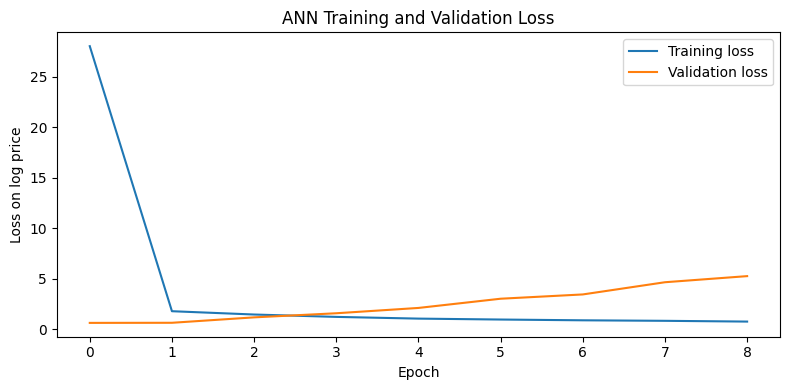

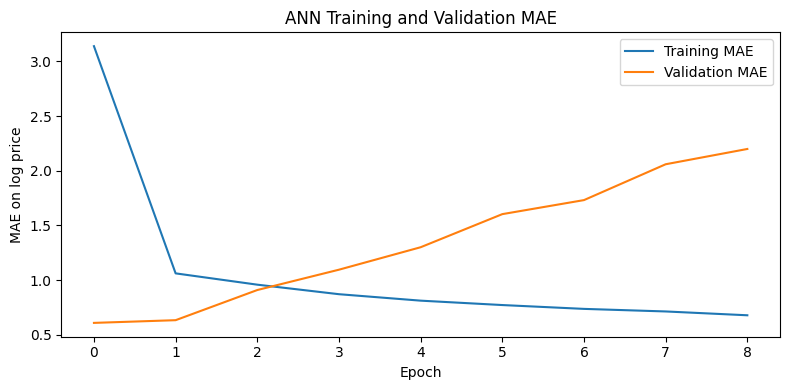

In [19]:
plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.title("ANN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss on log price")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(history.history["mae"], label="Training MAE")
plt.plot(history.history["val_mae"], label="Validation MAE")
plt.title("ANN Training and Validation MAE")
plt.xlabel("Epoch")
plt.ylabel("MAE on log price")
plt.legend()
plt.tight_layout()
plt.show()

### 20. Evaluate on the test set

In [20]:
predicted_log = model.predict(X_test_ready, verbose=0).reshape(-1)
y_pred = np.expm1(predicted_log)
y_actual = y_test.to_numpy()

mae = mean_absolute_error(y_actual, y_pred)
rmse = np.sqrt(mean_squared_error(y_actual, y_pred))
r2 = r2_score(y_actual, y_pred)
mape = np.mean(np.abs((y_actual - y_pred) / y_actual)) * 100

metrics = pd.DataFrame([{
    "MAE": mae,
    "RMSE": rmse,
    "R2": r2,
    "MAPE_percent": mape
}])

display(metrics.round(3))
print(f"MAE: predictions are off by about {mae:,.0f} price units on average.")
print("These scores apply to the held-out test data, not to every property on the market.")

,MAE,RMSE,R2,MAPE_percent
0,8225067.288,3.039979e+07,-0.065,50.302


MAE: predictions are off by about 8,225,067 price units on average.
These scores apply to the held-out test data, not to every property on the market.


### 21. Compare ANN with a simple baseline

The baseline always predicts the median price from the training data. It gives a simple reference point for deciding whether the ANN is useful.

In [21]:
baseline_pred = np.full(len(y_test), y_train.median())

baseline_results = pd.DataFrame([
    {
        "Model": "Training median baseline",
        "MAE": mean_absolute_error(y_test, baseline_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, baseline_pred)),
        "R2": r2_score(y_test, baseline_pred)
    },
    {
        "Model": "ANN",
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }
])

display(baseline_results.round(3))

,Model,MAE,RMSE,R2
0,Training median baseline,8463853.799,3.006845e+07,-0.041
1,ANN,8225067.288,3.039979e+07,-0.065


### 22. Actual price vs predicted price

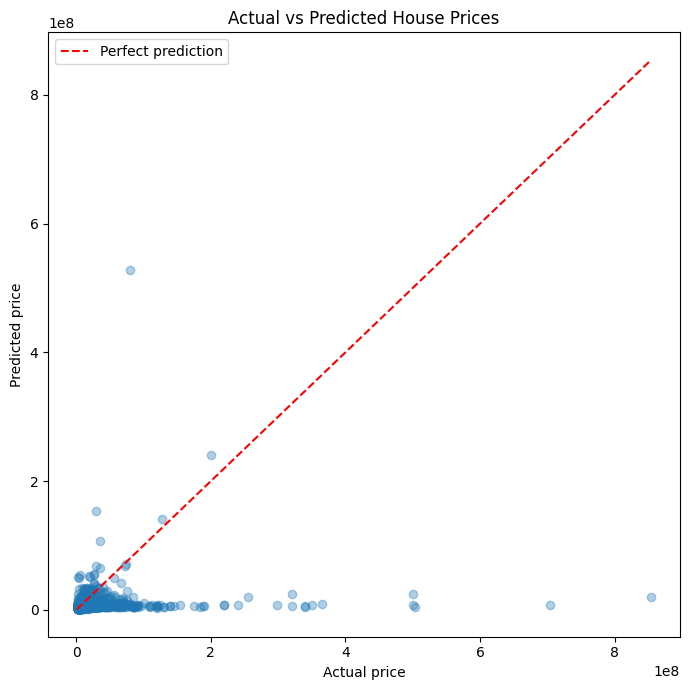

In [22]:
plt.figure(figsize=(7, 7))
plt.scatter(y_actual, y_pred, alpha=0.35)
low = min(y_actual.min(), y_pred.min())
high = max(y_actual.max(), y_pred.max())
plt.plot([low, high], [low, high], "r--", label="Perfect prediction")
plt.title("Actual vs Predicted House Prices")
plt.xlabel("Actual price")
plt.ylabel("Predicted price")
plt.legend()
plt.tight_layout()
plt.show()

### 23. Check errors by city

In [23]:
error_table = X_test[["City", "City_Location", "Area", "No. of Bedrooms"]].copy()
error_table["Actual_Price"] = y_actual
error_table["Predicted_Price"] = y_pred
error_table["Absolute_Error"] = np.abs(y_actual - y_pred)

city_errors = error_table.groupby("City").agg(
    Test_Listings=("Actual_Price", "size"),
    MAE=("Absolute_Error", "mean"),
    Median_Absolute_Error=("Absolute_Error", "median")
).sort_values("MAE", ascending=False)

display(city_errors.round(2))

,Test_Listings,MAE,Median_Absolute_Error
City,,,
Delhi,654,16777306.92,3529341.50
Mumbai,1016,9385832.76,3938632.25
Hyderabad,314,6156974.44,2595442.75
Bangalore,813,5967362.30,2655283.50
Kolkata,931,5753787.65,1924505.50
Chennai,643,5135104.96,2034465.50


### 24. Inspect the biggest prediction errors

In [24]:
display(
    error_table.sort_values("Absolute_Error", ascending=False)
    .head(15)
    .round(2)
)

,City,City_Location,Area,No. of Bedrooms,Actual_Price,Predicted_Price,Absolute_Error
12659,Delhi,Delhi | Vasant Kunj,6852,4,854599999.0,20352460.0,834247539.0
13514,Delhi,Delhi | West End,1490,3,704400000.0,7346567.5,697053432.5
18463,Kolkata,Kolkata | Barrackpore,975,2,504000000.0,4969793.5,499030206.5
13764,Delhi,Delhi | Mansarovar garden,3460,4,500000000.0,7210651.5,492789348.5
12965,Delhi,Delhi | Greater Kailash,7259,5,500000000.0,24906412.0,475093588.0
14522,Hyderabad,Hyderabad | Kukatpally,9400,8,80000000.0,527332384.0,447332384.0
12788,Delhi,Delhi | Karampura,2800,4,365000000.0,8479193.0,356520807.0
12802,Delhi,Delhi | Punjabi Bagh,1400,3,350000000.0,7084422.0,342915578.5
11680,Delhi,Delhi | Uttam Nagar,900,3,340000000.0,3918142.5,336081857.5
11654,Delhi,Delhi | Mahavir Enclave,450,2,340000000.0,5464479.5,334535520.5


### 25. Try predicting one property

In [25]:
# Use an actual held-out property as an example.
sample_property = X_test.iloc[[0]].copy()
actual_price = float(y_test.iloc[0])

sample_ready = preprocessor.transform(sample_property).astype(np.float32)
sample_pred_log = float(model.predict(sample_ready, verbose=0).reshape(-1)[0])
sample_pred_price = float(np.expm1(sample_pred_log))

print("City:", sample_property["City"].iloc[0])
print("Location:", sample_property["City_Location"].iloc[0])
print("Area:", sample_property["Area"].iloc[0])
print("Bedrooms:", sample_property["No. of Bedrooms"].iloc[0])
print("Actual price:", round(actual_price, 2))
print("Predicted price:", round(sample_pred_price, 2))
print("Absolute error:", round(abs(actual_price - sample_pred_price), 2))

City: Kolkata
Location: Kolkata | Rajpur
Area: 835
Bedrooms: 2
Actual price: 5287000.0
Predicted price: 4881888.71
Absolute error: 405111.29


### 26. Save the model and results

In [27]:
from pathlib import Path
import joblib

model_folder = Path("models")
output_folder = Path("outputs")
model_folder.mkdir(exist_ok=True)
output_folder.mkdir(exist_ok=True)

model.save("location_based_price_ann.keras")
joblib.dump(preprocessor, model_folder / "location_price_preprocessor.joblib")

metrics.to_csv(output_folder / "ann_test_metrics.csv", index=False)
baseline_results.to_csv(output_folder / "baseline_comparison.csv", index=False)
city_summary.to_csv(output_folder / "city_price_summary.csv")
location_summary.to_csv(output_folder / "location_price_summary.csv", index=False)
error_table.sort_values("Absolute_Error", ascending=False).head(100).to_csv(
    output_folder / "largest_prediction_errors.csv", index=False
)

print("Saved the trained model, preprocessing pipeline and analysis results.")

Saved the trained model, preprocessing pipeline and analysis results.


### Conclusion

I first explored house prices by city and location, then checked how area, bedrooms, resale status, and listed facilities relate to prices. I used those features to train an ANN and evaluated it on a separate test set.

Before making a final claim, compare the ANN's MAE and RMSE with the median-price baseline. If the ANN does not improve the results, it should not be described as the better model.

**Limitations:** The dataset does not include latitude/longitude, exact sale dates, or a confirmed price unit. `Location` and `City` are therefore used as categories rather than geographic coordinates. The `9` values in amenity columns are treated as unknown based on their pattern; this should be confirmed from the original data dictionary. The model estimates prices for records similar to this dataset and should not be treated as a guaranteed current market valuation.